#### K-Means Clustering

Import  Needed Packages

In [ ]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import os

Load Data

In [2]:
# Set working directory 
path = r'E:\Brain Cancer\GSE_124814\Py-Machine'
os.chdir(path)
print(os.listdir())

# Load data
data = pd.read_csv("Pro_Data.csv")

print(data.head(5))
print(data.shape)

['01-Python-MachineLearning.ipynb', '02-SimpleLinearRegression.ipynb', 'GSE124814_HW_expr_matrix.tsv', 'GSE124814_sample_descriptions.xlsx', 'Pro_Data.csv']


C:\Users\Asus\AppData\Local\Temp\ipykernel_1860\970915885.py:7: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("Pro_Data.csv")


    Samples      source name gender brain region      A1CF       A2M  \
0  Sample_1  Medulloblastoma      F   cerebellum -0.019300  0.289494   
1  Sample_2  Medulloblastoma      M   cerebellum  0.059848  0.230734   
2  Sample_3  Medulloblastoma      F   cerebellum -0.092846 -0.089454   
3  Sample_4  Medulloblastoma      M   cerebellum -0.097767  0.314725   
4  Sample_5  Medulloblastoma      M   cerebellum  0.118738  1.391229   

      A2ML1    A4GALT     A4GNT      AAAS  ...    ZSWIM6    ZSWIM8      ZW10  \
0  0.213732 -0.402028  0.030517 -0.112330  ... -0.367363  0.551670  0.184700   
1  0.040908 -0.381666 -0.145988  0.092463  ... -1.109660  0.286734 -0.076648   
2 -0.086623 -0.586763 -0.245097 -0.015891  ...  0.427460  0.234605 -0.115306   
3 -0.094998 -0.784063 -0.297410  0.557690  ... -0.266578 -0.898953  0.511287   
4  0.038038 -0.242232 -0.050874  0.067459  ... -0.718445  0.300914  0.471590   

     ZWILCH     ZWINT      ZXDC    ZYG11A    ZYG11B       ZYX      ZZZ3  
0  0.754473 

#### Understanding Data

* samples: include number of samples derived frome pationts and normal cases
* source name: Medulloblastoma(cancer type) and normal
* gender: M(male) and F(female)
* brain region: the area of the brain where the cancer has develope 

We aim to perform **K-Means clustering** on gene expression data to distinguish between tumor and normal samples. The dataset consists of 1,445 samples (tumor and normal) across 14,887 genes. The goal is to identify natural groupings in the data and evaluate whether K-Means can separate tumor from normal samples based on their expression profiles.

#### Pre-processing

In [9]:
# Genes Columns
Genes = data.iloc[:, 4:]
Genes.head(5)

,A1CF,A2M,A2ML1,A4GALT,A4GNT,AAAS,AACS,AADAC,AADACL2,AADAT,...,ZSWIM6,ZSWIM8,ZW10,ZWILCH,ZWINT,ZXDC,ZYG11A,ZYG11B,ZYX,ZZZ3
0,-0.019300,0.289494,0.213732,-0.402028,0.030517,-0.112330,0.327182,0.243028,-0.379652,-0.779346,...,-0.367363,0.551670,0.184700,0.754473,-0.130259,0.170434,0.043495,0.089644,-0.482902,-0.221186
1,0.059848,0.230734,0.040908,-0.381666,-0.145988,0.092463,1.071961,0.072346,-0.196808,0.020437,...,-1.109660,0.286734,-0.076648,1.833178,0.361207,-0.197682,-0.004007,-0.652674,0.204452,-0.492102
2,-0.092846,-0.089454,-0.086623,-0.586763,-0.245097,-0.015891,0.164045,-0.078648,-0.020103,0.239080,...,0.427460,0.234605,-0.115306,1.456536,0.120229,-0.086808,0.114014,0.892811,-0.391065,-0.287110
3,-0.097767,0.314725,-0.094998,-0.784063,-0.297410,0.557690,1.297581,0.213874,0.050398,0.998270,...,-0.266578,-0.898953,0.511287,0.681847,0.551090,-0.275844,-0.042835,-0.635228,-0.248843,-0.396709
4,0.118738,1.391229,0.038038,-0.242232,-0.050874,0.067459,0.037079,0.061993,-0.114732,-0.777357,...,-0.718445,0.300914,0.471590,-0.227464,-0.333867,-0.148096,-0.389286,0.963603,0.060100,-0.097176


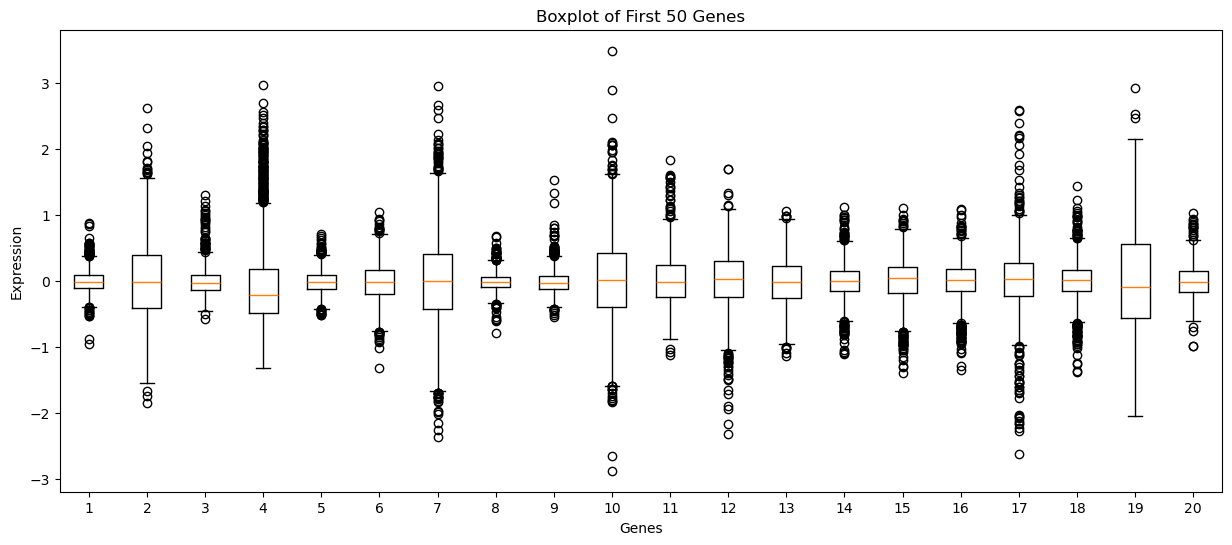

means: 
 A1CF      0.000524
A2M       0.009258
A2ML1     0.002390
A4GALT   -0.014544
A4GNT    -0.003882
            ...   
ZXDC      0.002260
ZYG11A   -0.000185
ZYG11B   -0.004413
ZYX       0.002932
ZZZ3      0.003897
Length: 14883, dtype: float64
stds: 
 A1CF      0.169937
A2M       0.603540
A2ML1     0.213152
A4GALT    0.715011
A4GNT     0.171150
            ...   
ZXDC      0.271670
ZYG11A    0.605365
ZYG11B    0.457234
ZYX       0.351401
ZZZ3      0.339937
Length: 14883, dtype: float64


In [29]:
# Quality Control
Genes_boxplot = Genes.iloc[:, :20]
plt.figure(figsize=(15, 6))
plt.boxplot(Genes_boxplot)
plt.xlabel("Genes")
plt.ylabel("Expression")
plt.title("Boxplot of First 50 Genes")
plt.show()

print("means: \n", Genes.mean(axis=0))
print("stds: \n", Genes.std(axis=0))

Gene expression data was standardized (Z-score) to ensure that genes with different scales contribute equally to the clustering.

In [30]:
from sklearn.preprocessing import StandardScaler
scale = StandardScaler()
DataScaled = scale.fit_transform(Genes)

PCA (Principal Component Analysis) was applied to reduce dimensions.

In [50]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca_data = pca.fit_transform(DataScaled)

pca_df = pd.DataFrame(
    pca_data,
    columns=["PC1", "PC2"],
    index=data.index
)
pca_df["Condition"] = data["source name"].values
pca_df.head(5)

,PC1,PC2,Condition
0,-27.831995,-12.886419,Medulloblastoma
1,-9.153931,-46.847818,Medulloblastoma
2,-32.994642,-34.882607,Medulloblastoma
3,50.210640,-81.000506,Medulloblastoma
4,-28.757478,6.657575,Medulloblastoma


<Figure size 1000x700 with 0 Axes>

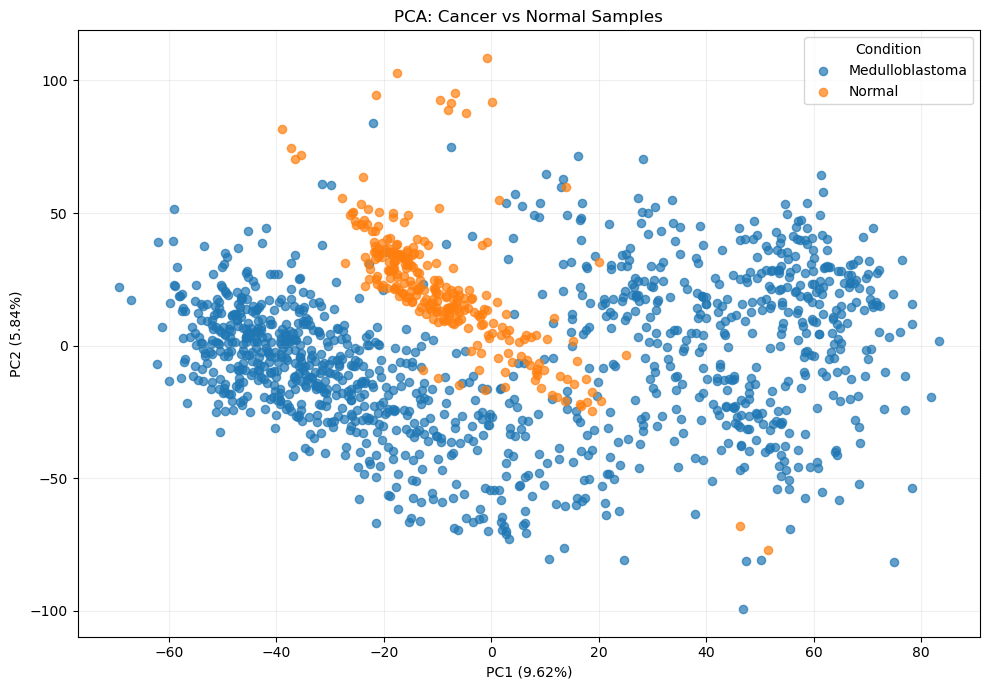

In [53]:
plt.figure(figsize=(10, 7))

for condition in pca_df["Condition"].unique():
    subset = pca_df[pca_df["Condition"] == condition]
    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=condition,
        alpha=0.7,
        s=35
    )
plt.xlabel( f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}%)" )
plt.ylabel( f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}%)" )
plt.title("PCA: Cancer vs Normal Samples")
plt.legend(title="Condition") 
plt.grid(alpha=0.2) 
plt.tight_layout() 
plt.show()

#### Modeling

In [62]:
from sklearn.cluster import KMeans

k_means = KMeans(init="k-means++", n_clusters=2, n_init=12)
pca_df["Label"] = k_means.fit_predict(
    pca_df[["PC1", "PC2"]]
)
pca_df.head(5)


c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


,PC1,PC2,Condition,Label
0,-27.831995,-12.886419,Medulloblastoma,1
1,-9.153931,-46.847818,Medulloblastoma,1
2,-32.994642,-34.882607,Medulloblastoma,1
3,50.210640,-81.000506,Medulloblastoma,0
4,-28.757478,6.657575,Medulloblastoma,1


C:\Users\Asus\AppData\Local\Temp\ipykernel_1860\467361185.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


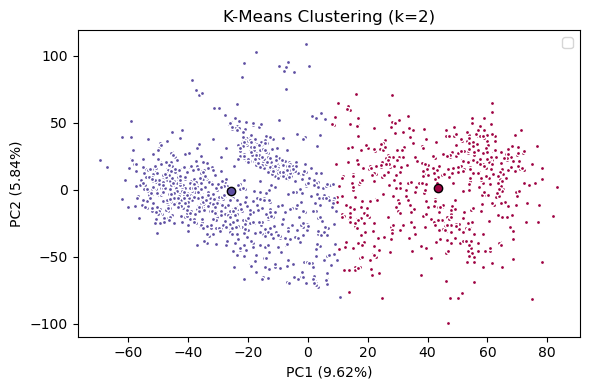

In [68]:
k_means_label = k_means.labels_
k_means_label

k_means_cluster_centers = k_means.cluster_centers_
k_means_cluster_centers

fig = plt.figure(figsize=(6, 4))
colors = plt.cm.Spectral(np.linspace(0,1, len(set(k_means.labels_))))
ax = fig.add_subplot(1,1,1)

for k, col in zip(range(len(k_means.cluster_centers_)), colors):
    my_members = (k_means.labels_ == k)
    cluster_center = k_means.cluster_centers_[k]
    ax.plot(pca_df.iloc[my_members, 0], pca_df.iloc[my_members, 1], 'w', markerfacecolor=col, marker='.')
    ax.plot(cluster_center[0], cluster_center[1], 'o', markerfacecolor=col,  markeredgecolor='k', markersize=6)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.2%})")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.2%})")
    ax.set_title(f"K-Means Clustering (k={clus_num})")
    ax.legend()
    plt.tight_layout()
plt.show()

#### Silhouette Score

c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\Asus\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows wi

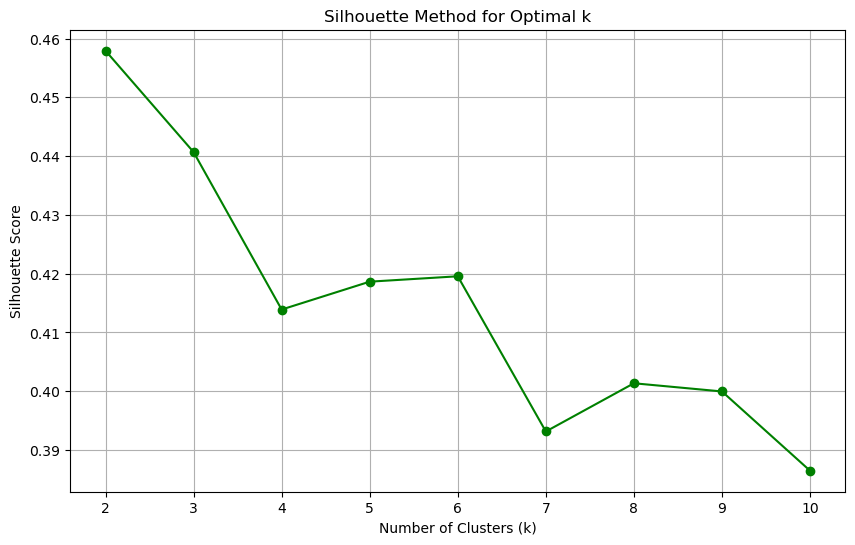

Best k: 2  Silhouette Score: 0.4579


In [70]:
from sklearn.metrics import silhouette_score

sil_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=12, random_state=42)
    labels = kmeans.fit_predict(pca_df[['PC1', 'PC2']])
    sil_scores.append(silhouette_score(pca_df[['PC1', 'PC2']], labels))

plt.figure(figsize=(10, 6))
plt.plot(K_range, sil_scores, marker='o', linestyle='-', color='g')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Method for Optimal k')
plt.grid(True)
plt.show()

best_k = K_range[sil_scores.index(max(sil_scores))]
print(f"Best k: {best_k}  Silhouette Score: {max(sil_scores):.4f}")